In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/2015.csv")
df.head()

,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


In [2]:
df.shape

(158, 12)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        158 non-null    str    
 1   Region                         158 non-null    str    
 2   Happiness Rank                 158 non-null    int64  
 3   Happiness Score                158 non-null    float64
 4   Standard Error                 158 non-null    float64
 5   Economy (GDP per Capita)       158 non-null    float64
 6   Family                         158 non-null    float64
 7   Health (Life Expectancy)       158 non-null    float64
 8   Freedom                        158 non-null    float64
 9   Trust (Government Corruption)  158 non-null    float64
 10  Generosity                     158 non-null    float64
 11  Dystopia Residual              158 non-null    float64
dtypes: float64(9), int64(1), str(2)
memory usage: 14.9 KB


In [4]:
df.describe()

,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,79.493671,5.375734,0.047885,0.846137,0.991046,0.630259,0.428615,0.143422,0.237296,2.098977
std,45.754363,1.145010,0.017146,0.403121,0.272369,0.247078,0.150693,0.120034,0.126685,0.553550
min,1.000000,2.839000,0.018480,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328580
25%,40.250000,4.526000,0.037268,0.545808,0.856823,0.439185,0.328330,0.061675,0.150553,1.759410
50%,79.500000,5.232500,0.043940,0.910245,1.029510,0.696705,0.435515,0.107220,0.216130,2.095415
75%,118.750000,6.243750,0.052300,1.158448,1.214405,0.811013,0.549092,0.180255,0.309883,2.462415
max,158.000000,7.587000,0.136930,1.690420,1.402230,1.025250,0.669730,0.551910,0.795880,3.602140


In [5]:
df.isna().sum()

Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Standard Error                   0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

In [6]:
df.columns.tolist()

['Country',
 'Region',
 'Happiness Rank',
 'Happiness Score',
 'Standard Error',
 'Economy (GDP per Capita)',
 'Family',
 'Health (Life Expectancy)',
 'Freedom',
 'Trust (Government Corruption)',
 'Generosity',
 'Dystopia Residual']

In [7]:
df = df.rename(columns ={
    "Happiness Rank": "rank",
    "Happiness Score": "score",
    "Standard Error": "std_error",
    "Economy (GDP per Capita)": "gdp",
    "Family":"family",
    "Health (Life Expectancy)": "health",
    "Freedom": "freedom",
    "Trust (Government Corruption)": "trust",
    "Generosity": "generosity",
    "Dystopia Residual": "dystopia",
    "Country":"country",
    "Region":"region",
})
print(df.duplicated().sum())

facteurs = ["gdp","family","health","freedom","trust","generosity","dystopia"]
ecart = (df[facteurs].sum(axis=1) - df["score"]).abs()
print(ecart.max())

df.to_csv("../data/2015_clean.csv",index=False)

0
0.0005099999999993443


In [8]:
df.groupby("region")["score"].mean().sort_values(ascending=False)

region
Australia and New Zealand          7.285000
North America                      7.273000
Western Europe                     6.689619
Latin America and Caribbean        6.144682
Eastern Asia                       5.626167
Middle East and Northern Africa    5.406900
Central and Eastern Europe         5.332931
Southeastern Asia                  5.317444
Southern Asia                      4.580857
Sub-Saharan Africa                 4.202800
Name: score, dtype: float64

In [9]:
df[facteurs + ["score"]].corr()["score"].sort_values(ascending=False)

score         1.000000
gdp           0.780966
family        0.740605
health        0.724200
freedom       0.568211
dystopia      0.530474
trust         0.395199
generosity    0.180319
Name: score, dtype: float64

In [10]:
print(np.mean(df["score"]),np.std(df["score"]))

5.375734177215189 1.1413809336358134


In [11]:
print(df.duplicated().sum())


0


In [12]:
print(ecart.max())

0.0005099999999993443


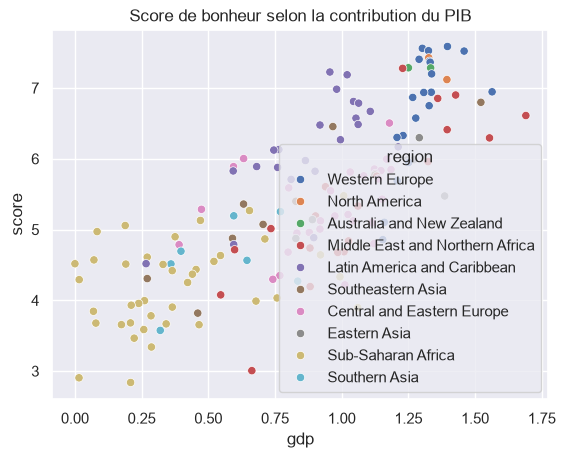

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

sns.scatterplot(data=df,x="gdp",y="score",hue="region")
plt.title("Score de bonheur selon la contribution du PIB")
plt.savefig("../images/score_vs_gdp.png",dpi=150, bbox_inches="tight")
plt.show()

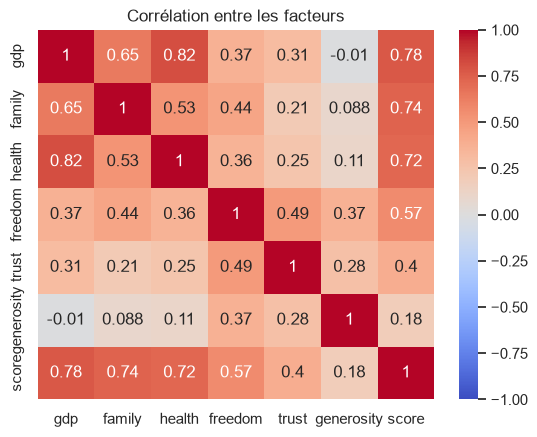

In [14]:
facteurs_sans_dystopia =["gdp","family","health","freedom","trust","generosity"]
sns.heatmap(df[facteurs_sans_dystopia + ["score"]].corr(),annot=True, cmap="coolwarm",vmin=-1,vmax=1)
plt.title("Corrélation entre les facteurs")
plt.savefig("../images/correlations.png",dpi=150,bbox_inches="tight")
plt.show()

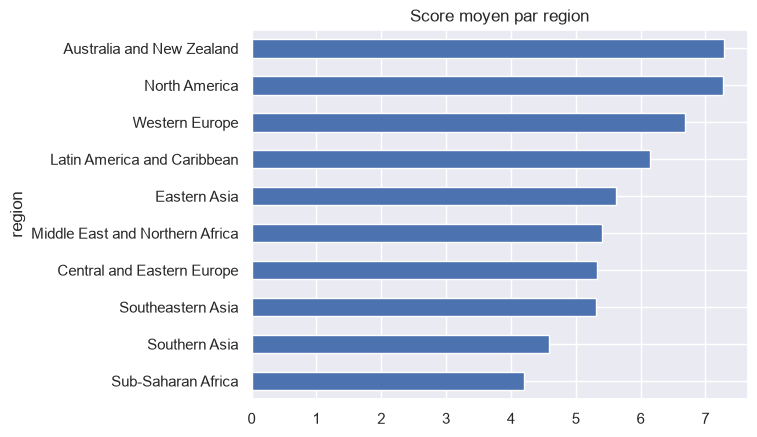

In [15]:
df.groupby("region")["score"].mean().sort_values().plot(kind="barh")
plt.title("Score moyen par region")
plt.savefig("../images/score_par_region.png",dpi=150,bbox_inches="tight")
plt.show()

In [16]:
df.groupby("region")["score"].agg(["mean","std","count"]).sort_values("std",ascending=False)

,mean,std,count
region,,,
Middle East and Northern Africa,5.406900,1.101382,20
Southeastern Asia,5.317444,0.950020,9
Western Europe,6.689619,0.824582,21
Latin America and Caribbean,6.144682,0.728560,22
Sub-Saharan Africa,4.202800,0.609557,40
Southern Asia,4.580857,0.570526,7
Central and Eastern Europe,5.332931,0.570446,29
Eastern Asia,5.626167,0.554053,6
North America,7.273000,0.217789,2


In [17]:
stats=df.groupby("region")["score"].agg(["mean","std","count"])
stats["mean_precision"] = stats["std"] / np.sqrt(stats["count"])
stats.sort_values("mean",ascending=False)

,mean,std,count,mean_precision
region,,,,
Australia and New Zealand,7.285000,0.001414,2,0.001000
North America,7.273000,0.217789,2,0.154000
Western Europe,6.689619,0.824582,21,0.179939
Latin America and Caribbean,6.144682,0.728560,22,0.155330
Eastern Asia,5.626167,0.554053,6,0.226191
Middle East and Northern Africa,5.406900,1.101382,20,0.246276
Central and Eastern Europe,5.332931,0.570446,29,0.105929
Southeastern Asia,5.317444,0.950020,9,0.316673
Southern Asia,4.580857,0.570526,7,0.215639


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error

X = df[["gdp","family","health","freedom","trust","generosity"]]
y= df["score"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

modele = LinearRegression()
modele.fit(X_train,y_train)

y_pred = modele.predict(X_test)

print("R2 :", r2_score(y_test,y_pred))
print("MAE:", mean_absolute_error(y_test,y_pred))

coefs=pd.Series(modele.coef_,index=X.columns).sort_values(ascending =False)

print(coefs)



R2 : 0.8294705100069293
MAE: 0.4023049853814401
family        1.261558
freedom       1.231449
health        1.019769
gdp           0.876149
trust         0.811955
generosity    0.635959
dtype: float64


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

modele_s = LinearRegression()
modele_s.fit(X_train_s, y_train)

coefs_s = pd.Series(modele_s.coef_, index=X.columns).sort_values(ascending=False)
print(coefs_s)
print("R2 :", r2_score(y_test, modele_s.predict(X_test_s)))

family        0.351961
gdp           0.342106
health        0.242389
freedom       0.184567
trust         0.100011
generosity    0.077909
dtype: float64
R2 : 0.8294705100069294


In [20]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
print(scores, scores.mean(), scores.std())

[0.82947051 0.76086    0.72166003 0.68354291 0.70501893] 0.7401104753714689 0.051356563809174846
